# Nastoyka: какой ассортимент выдержит совместную закупку?

Для одного нового меню бара Санкт-Петербурга сравниваем **10 настоек: 8 основных и 2 премиальные**, с целевой средней ценой проданной порции **250 ₽ за 50 мл**. Исходные 200 ₽ — ориентир задачи, не измеренная цена рынка.

**Предварительный результат:** вариант B сочетает роли вкусов при первой корзине 17 009 ₽ на 10 л сценарного выхода. Экономия варианта A — лишь 16 ₽; вариант C с авторским якорем «Черника — сыр» требует на 1 302 ₽ больше B. Окончательное меню пока не утверждаем: выходы не измерены, часть рецептур модельная, цены не являются договорными закупочными предложениями.

Это продолжение существующего исследования публичных отзывов. Новые отзывы не собираются, старые ID и Excel сохраняются. Постоянные цели закреплены в [плане](docs/project_plan.md); формулы, источники и ограничения — в [методике экономики](docs/economics_methodology.md).

Python 3.12: установить `requirements.txt`, открыть Notebook из корня проекта и выполнить сверху вниз. Первый блок запускает всю воспроизводимую цепочку SQL → Python → таблицы и рисунки; ниже разбираем её результаты по этапам.

In [1]:
from pathlib import Path
import json
import io
import contextlib
import pandas as pd
from IPython.display import display, Image, Markdown
from scripts import economics as e

ROOT = Path.cwd()
assert (ROOT / "data/nastoyki_reviews.xlsx").exists(), "Запустите Notebook из корня Nastoyka"
pd.set_option("display.max_rows", 25)
pd.set_option("display.max_columns", 12)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
with contextlib.redirect_stdout(io.StringIO()):
    result = e.run()
config = e.read_config()
out = ROOT / "data/economics/results"
candidates = pd.read_csv(out / "candidates.csv")
recipes = pd.read_csv(out / "recipe_costs.csv")
menus = pd.read_csv(out / "menu_summary.csv")
items = pd.read_csv(out / "menu_items.csv")
procurement = pd.read_csv(out / "procurement.csv")
scenarios = pd.read_csv(out / "price_scenarios.csv")
print("Расчёт завершён; допустимых сочетаний:", result["feasible_menu_count"])
print("Статус:", result["status"])
print("Исходные файлы совпадают с baseline:", bool(e.check_baseline()))

Расчёт завершён; допустимых сочетаний: 102
Статус: preliminary_scenario_not_approved
Исходные файлы совпадают с baseline: True


## 1. Что есть в базе и чего она не доказывает

Источник мнений — существующая книга `data/nastoyki_reviews.xlsx`. Текущие показатели проверены по ней, а SQL-срез сверяется с прежней сводкой. Не редактируем старые CSV: команда `workbook.py refresh` их перезаписывает из Excel.

Подтверждённый источник означает найденную публикацию или видимый фрагмент, не доказанную реальность визита. Публикации и упоминания не равны людям, объёму продаж или предпочтениям всех гостей. Из 358 подтверждённых публикаций 275 прочитаны как видимые фрагменты. Исторические данные и текущие меню хранятся отдельно.

In [2]:
frames = e.workbook_frames()
display(pd.Series(result["source_counts"], name="Проверенная база"))
print("Подтверждённых публикаций с видимым фрагментом:",
      ((frames["reviews"].source_status == "verified") &
       (frames["reviews"].text_completeness == "visible_excerpt")).sum())
assert frames["reviews"]["ID отзыва"].is_unique
assert frames["mentions"]["ID"].is_unique
print("Исходные отзывы:", len(frames["reviews"]), "; упоминания:", len(frames["mentions"]))

reviews                       368
verified_reviews              358
mentions                      468
verified_concrete_mentions    198
verified_flavors              114
strict_mentions               143
menu_rows                      95
current_venues                 30
Name: Проверенная база, dtype: int64

Подтверждённых публикаций с видимым фрагментом: 275
Исходные отзывы: 368 ; упоминания: 468


Сохранены все 368 отзывов и 468 упоминаний, включая неподтверждённые. Для анализа конкретных вкусов доступны 198 упоминаний и 114 названий; строгий срез содержит 143 упоминания. Это ограниченные и неравномерные базы. Строгий срез отбирает текущие заведения, высокую уверенность и отсутствие прежних флагов; он не гарантирует свежесть каждого отзыва.

## 2. SQL-подготовка и 15 кандидатов

Временная SQLite-база связывает упоминание с отзывом и заведением. Фильтры повторяют существующую методику. Голос одного события по вкусу учитывается один раз. Подробная связь до `mention_id/review_id/venue_id` сохранена в `candidate_evidence.csv`, без создания новой таблицы отзывов.

```sql
-- Источник таблиц — исходная Excel-книга; имена и значения не перенормализуются.
-- Строгий срез повторяет scripts/workbook.py: это текущие заведения, НЕ давность отзывов.
CREATE TEMP VIEW verified_concrete AS
SELECT m.*, r.event_group, r.platform_verification, r.bias_flag,
       COALESCE(NULLIF(r.event_group,''), r.review_id) AS event_key,
       CASE WHEN m.confidence='high' AND v.sample_current='yes'
                  AND COALESCE(r.platform_verification,'') <> 'not_passed'
                  AND COALESCE(r.bias_flag,'') = '' THEN 1 ELSE 0 END AS strict_flag
FROM mentions m
JOIN reviews r ON r.review_id=m.review_id AND r.venue_id=m.venue_id
JOIN venues v ON v.venue_id=m.venue_id
WHERE m.source_status='verified' AND r.source_status='verified'
  AND COALESCE(r.duplicate_of,'')='' AND m.specificity='concrete'
  AND COALESCE(m.normalized_flavor,'') <> '';


```

,candidate_id,normalized_flavor,verified_mentions,positive,negative,mixed,unique_reviews,unique_venues,tasting_positive,strict_mentions,strict_positive
0,C01,Хреновуха,7,5,1,1,7,6,5,6,5
1,C02,Вишня,4,3,0,0,4,4,3,1,1
2,C03,Малина,6,4,0,0,6,3,4,5,3
3,C04,Лимончелло,4,4,0,0,4,4,4,3,3
4,C05,Щавель,7,5,1,0,7,3,5,7,5
5,C06,Халва,6,5,0,0,6,3,5,6,5
6,C07,Черника — сыр,6,4,0,1,6,1,4,3,1
7,C08,Маракуйя,5,4,0,0,5,2,4,3,2
8,C09,Яблоко — базилик,3,3,0,0,3,1,3,3,3
9,C10,Свёкла — хрен,3,3,0,0,3,2,3,2,2


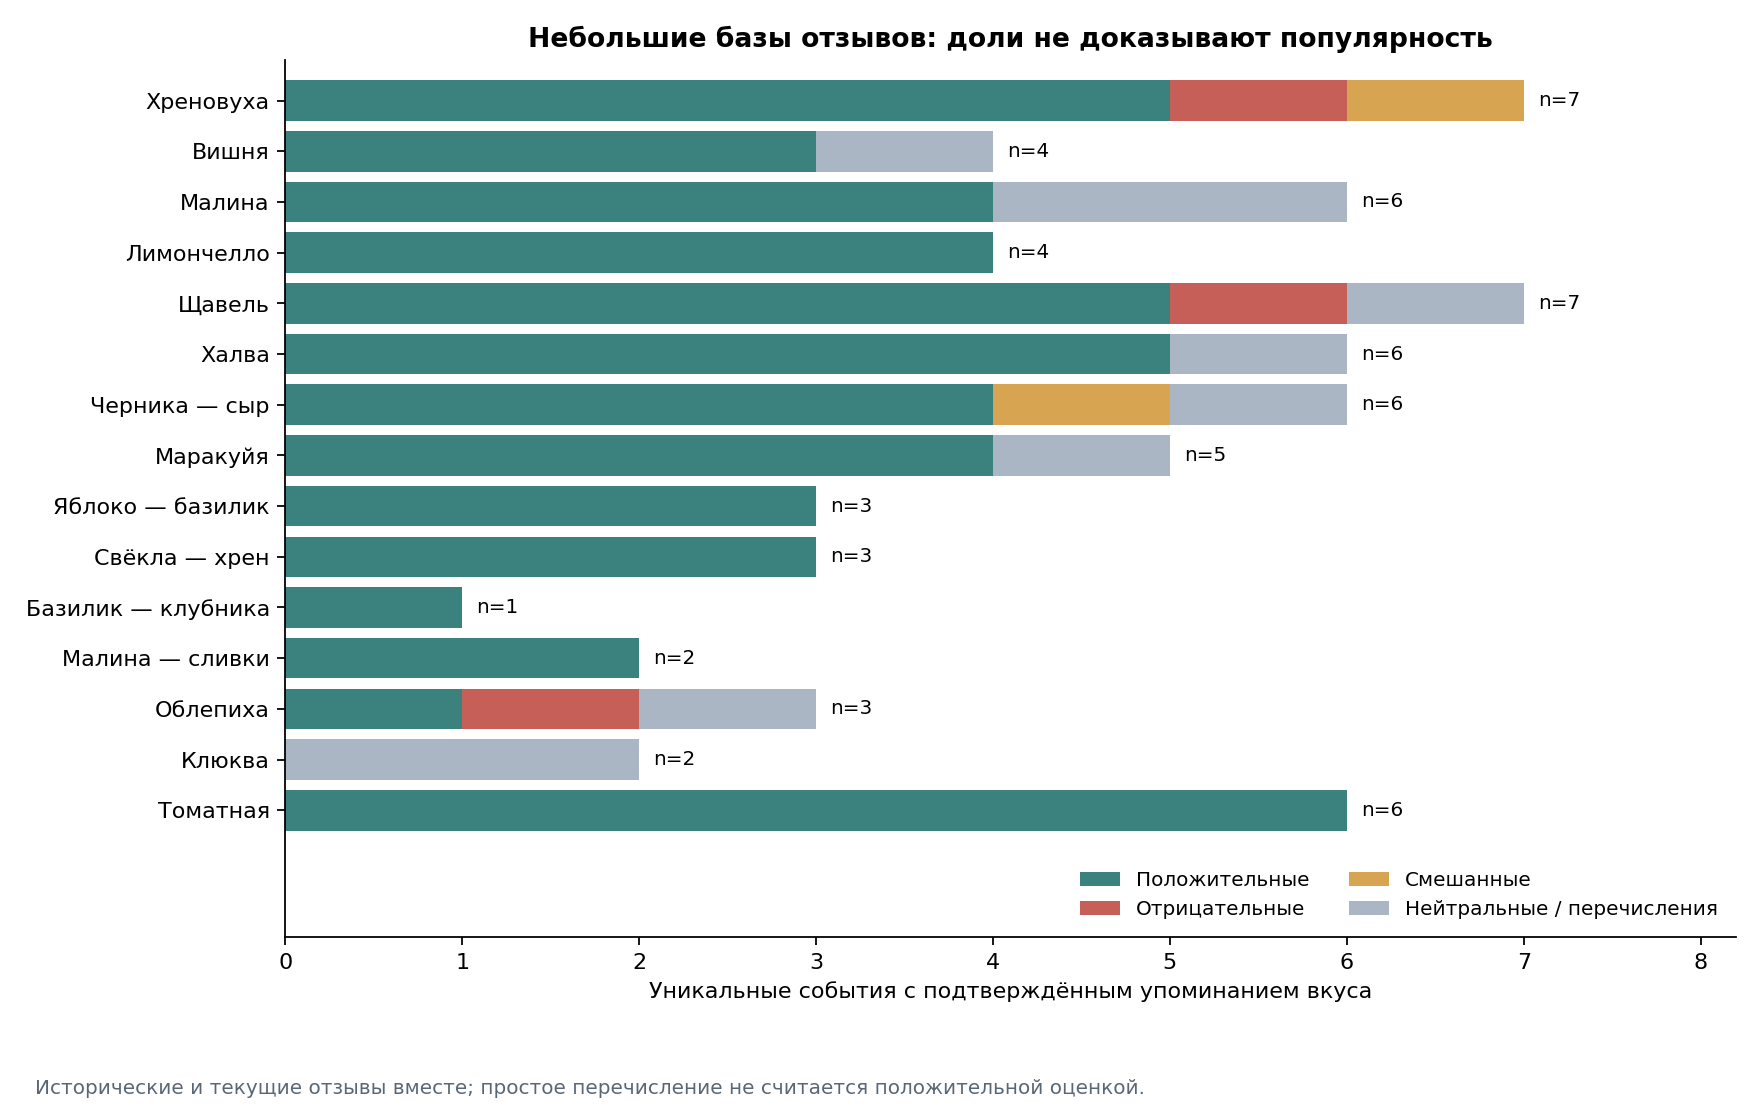

In [3]:
sql = (ROOT / "scripts/candidates.sql").read_text(encoding="utf-8")
display(Markdown("```sql" + chr(10) + sql.split("-- Один вкус")[0] + chr(10) + "```"))
display(candidates[["candidate_id","normalized_flavor","verified_mentions","positive","negative","mixed",
                    "unique_reviews","unique_venues","tasting_positive","strict_mentions","strict_positive"]])
display(Image(filename=str(ROOT / "figures/economics/reviews.png")))

Хреновуха и щавель имеют по семь подтверждённых упоминаний, но даже это небольшие базы. У клюквы нет явно положительных оценок — перечисления не превращаются в поддержку. У томатной шесть положительных упоминаний из одного заведения; после строгих фильтров остаётся одно.

Кандидаты выбраны по сочетанию роли, свидетельств и совместимости, а не только по числу упоминаний. Уверенность в рыночных выводах низкая. `tasting_positive` отдельно ограничен дегустационным свидетельством; колонки общего тона и строгого среза не подменяют этот показатель.

## 3. Матрица ролей

Одна основная экспертная роль и дополнительные признаки позволяют увидеть похожие позиции. Прежняя категория словаря сохраняется. Например, десертная роль «Черника — сыр» и сливочный состав расчётного варианта — наша гипотеза, не восстановленный коммерческий рецепт.

,normalized_flavor,category,primary_role,classic,unusual,creamy,similar_candidates
0,Хреновуха,пряная,пряная,1,0,0,C10
1,Вишня,ягодная,ягодная,1,0,0,C03|C13|C14
2,Малина,ягодная,ягодная,1,0,0,C02|C11|C12
3,Лимончелло,цитрусовая,цитрусовая,1,0,0,NaN
4,Щавель,травяная,травяная,0,1,0,C09|C11
5,Халва,десертная,десертная,0,1,0,C07|C12
6,Черника — сыр,ягодная,десертная,0,1,1,C06|C12
7,Маракуйя,фруктовая,фруктовая,0,0,0,C09
8,Яблоко — базилик,фруктовая,фруктовая,0,1,0,C05|C11
9,Свёкла — хрен,пряная,пряная,0,1,0,C01|C15


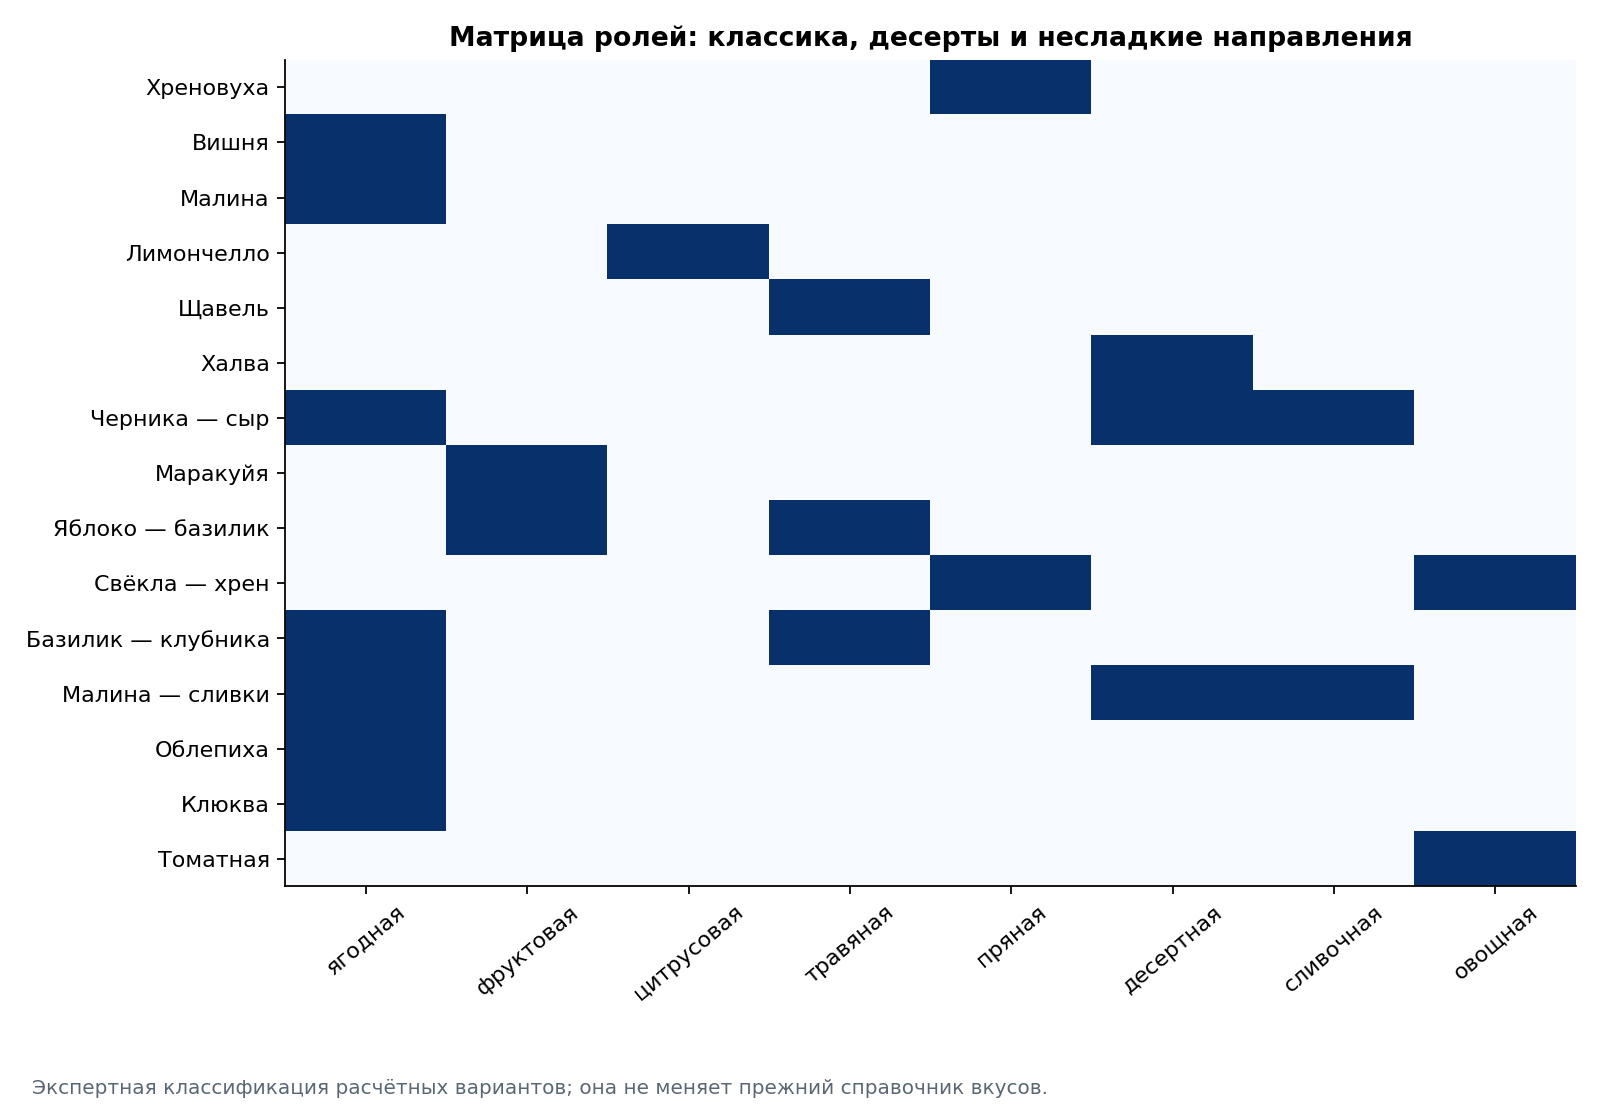

In [4]:
display(candidates[["normalized_flavor","category","primary_role","classic","unusual","creamy","similar_candidates"]])
display(Image(filename=str(ROOT / "figures/economics/flavor_matrix.png")))

Ягодных альтернатив много; цитрусовое и травяное направления представлены лимончелло и щавелем. Поэтому ограничения разнообразия важны: без них дешёвые сходные позиции могли бы занять половину меню. Дополнительные роли базилика, овощей и десертов не меняют фактическую статистику отзывов.

## 4. Рецептурные источники и цены

Для щавеля, халвы, облепихи и клюквы найдены количественные опубликованные составы. Четыре варианта адаптированы; для семи открытый количественный рецепт не установлен, их составы модельные. **Измеренного выхода и проверенной в баре технологической карты нет ни у одной позиции.** Сыр, вид халвы и замороженное сырьё могут отличаться от подразумеваемого в публикациях.

В `ingredients.csv` — 21 публичная цена с источником, датой и фасовкой. В основном это СПб; для «ВкусВилла» регион не выбран. Хрен по 1 кг и весовые шаги примерно по 100 г — явно обозначенные допущения заказа, не подтверждённые закрытые упаковки. Поставки и минимальные суммы заказа требуют согласования.

In [5]:
sources = pd.DataFrame(json.loads((ROOT / "data/economics/recipe_sources.json").read_text())["recipes"])
display(sources[["candidate_id","composition_status","source_status","source_url"]])
prices = pd.read_csv(out / "price_catalog.csv")
display(prices[["ingredient_id","supplier","package_price_rub","package_quantity","unit",
                "rub_per_base_unit","region_status","procurement_unit_status"]])
print("Опубликованных количественных составов:", result["published_quantity_recipes"])
print("Рецептур с измеренным выходом:", result["recipes_with_measured_yield"])

,candidate_id,composition_status,source_status,source_url
0,C01,model_adaptation,published_ranges,https://www.iamcook.ru/showrecipe/26613
1,C02,model_adaptation,published_incomplete,https://www.edimdoma.ru/retsepty/60273-vishnev...
2,C03,model_adaptation,published_other_proportions,https://alcofan.com/recepty-nastoek-maliny-na-...
3,C04,model_adaptation,published_partial_units,https://alcofan.com/prigotovlenie-domashnego-l...
4,C05,published_quantities,published_quantities,https://alcofan.com/kak-sdelat-nastojku-iz-shh...
5,C06,published_quantities,published_quantities,https://www.rbc.ru/wine/news/6718b1f19a7947d25...
6,C07,model_only,not_found,None
7,C08,model_only,not_found,None
8,C09,model_only,not_found,None
9,C10,model_only,not_found,None


,ingredient_id,supplier,package_price_rub,package_quantity,unit,rub_per_base_unit,region_status,procurement_unit_status
0,vodka,Декантер СПб,726,500,ml,1.45,SPb,fixed_package
1,sugar,АкваБалт,71,1,kg,0.07,SPb,fixed_package
2,water,ВкусВилл,117,5,l,0.02,region_not_selected,fixed_package
3,honey,ВкусВилл,274,200,g,1.37,region_not_selected,fixed_package
4,horseradish,Мультифрукт СПб,1900,1,kg,1.90,SPb,assumed_1kg_order_unit
5,lemon,ФрутСтар,20,100,g,0.20,SPb,approx_weight_increment
6,cherry,Дарим Лето,572,1,kg,0.57,SPb,fixed_package
7,raspberry,Дарим Лето,838,1,kg,0.84,SPb,fixed_package
8,sorrel,ФрутСтар,99,100,g,0.99,SPb,approx_weight_increment
9,halva,ВкусВилл,83,250,g,0.33,region_not_selected,fixed_package


Опубликованных количественных составов: 4
Рецептур с измеренным выходом: 0


Пустые цены не заменяются нулями. По сыру использована обычная показанная цена 248 ₽, а не 159 ₽ по карте; по мёду — 274 ₽ открытой страницы, а не 260 ₽ поискового кэша. Это розничные ориентиры, не обещание закупки бара по указанной цене.

## 5. Себестоимость с учётом выхода

Количество каждого ингредиента хранится в `config.json` в г или мл согласно справочнику. Литры и килограммы переводятся отдельно; плотность не подставляется. Граммы и миллилитры не складываются для получения выхода.

`ready_ml = nominal_product_ml × (1 − loss_fraction)`

`стоимость 50 мл = стоимость исходной партии / ready_ml × 50`

Номинальный объём и потери — сценарные параметры, которые нужно заменить измерениями пробных партий. В стоимость входят все исходные ингредиенты; фильтрационные потери не списываются второй раз. Маржа — до остальных расходов бара, не чистая прибыль.

,normalized_flavor,batch_ingredient_cost_rub,nominal_product_ml,loss_fraction,ready_ml,cost_liter_rub,cost_50ml_rub,price_rub,material_margin_fraction,yield_status
0,Хреновуха,867.40,520,0.08,478.40,"1,813.13",90.66,230,0.61,assumed_unmeasured
1,Вишня,933.30,700,0.10,630.00,"1,481.43",74.07,230,0.68,assumed_unmeasured
2,Малина,984.50,700,0.12,616.00,"1,598.21",79.91,230,0.65,assumed_unmeasured
3,Лимончелло,"1,191.82",1240,0.05,"1,178.00","1,011.73",50.59,230,0.78,assumed_unmeasured
4,Щавель,962.00,590,0.10,531.00,"1,811.68",90.58,230,0.61,assumed_unmeasured
5,Халва,"1,048.50",850,0.15,722.50,"1,451.21",72.56,330,0.78,assumed_unmeasured
6,Черника — сыр,"1,270.84",900,0.15,765.00,"1,661.23",83.06,330,0.75,assumed_unmeasured
7,Маракуйя,"1,031.21",950,0.10,855.00,"1,206.09",60.30,330,0.82,assumed_unmeasured
8,Яблоко — базилик,880.83,720,0.10,648.00,"1,359.31",67.97,230,0.70,assumed_unmeasured
9,Свёкла — хрен,822.65,650,0.10,585.00,"1,406.24",70.31,230,0.69,assumed_unmeasured


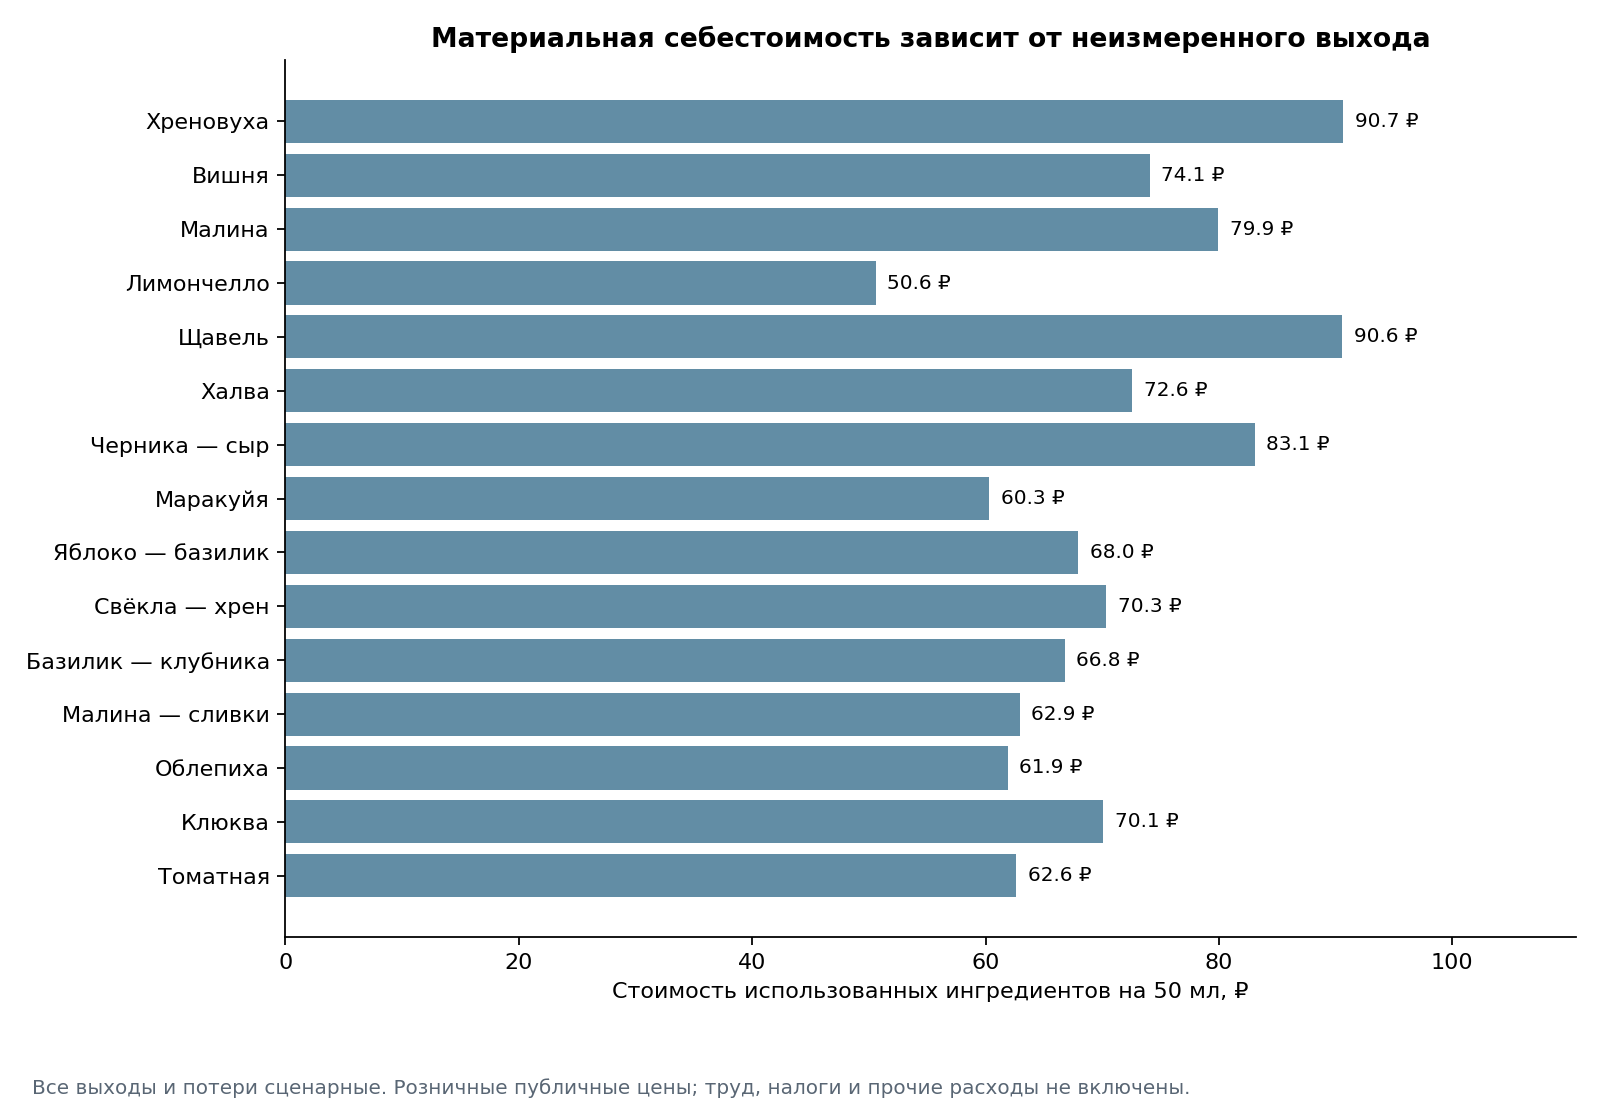

In [6]:
display(recipes[["normalized_flavor","batch_ingredient_cost_rub","nominal_product_ml","loss_fraction","ready_ml",
                 "cost_liter_rub","cost_50ml_rub","price_rub","material_margin_fraction","yield_status"]])
display(Image(filename=str(ROOT / "figures/economics/costs.png")))
assert recipes.yield_status.eq("assumed_unmeasured").all()
assert recipes.cost_50ml_rub.gt(0).all()

Сценарная материальная себестоимость 50 мл лежит примерно между 50,59 и 90,66 ₽. В исходных условиях все позиции проходят экспертный порог 60% материальной маржинальности, но хреновуха и щавель близки к нему. Эти числа не подтверждают технологическую пригодность состава или прибыльность бизнеса.

## 6. Закупочная совместимость и три меню

Для сравнения производим по 1 л пригодного выхода каждой выбранной настойки — 10 л на меню. Сначала суммируем общую потребность, затем округляем упаковки. Оставшееся сырьё — запас; его пригодность и использование в следующих циклах не доказаны.

В совместимость не включаем водку, сахар и воду. Дорогой компонент определяется порогом 75-го процентиля цены закупочной единицы — сейчас 581,75 ₽. Если одна рецептура создаёт не менее 80% потребности в нём, она считается требующей специфической дорогой закупки. Таких рецептур допускается максимум две.

A минимизирует первый заказ. B использует экспертные веса отзывов, направлений, совместимости и денежных затрат в пределах 120% A. C — отдельный авторский сценарий с обязательной «Черникой — сыром» в пределах 130% A. Полный перебор 990 сочетаний оставил 102 допустимых. Веса и якорь не выдаются за измеренные предпочтения.

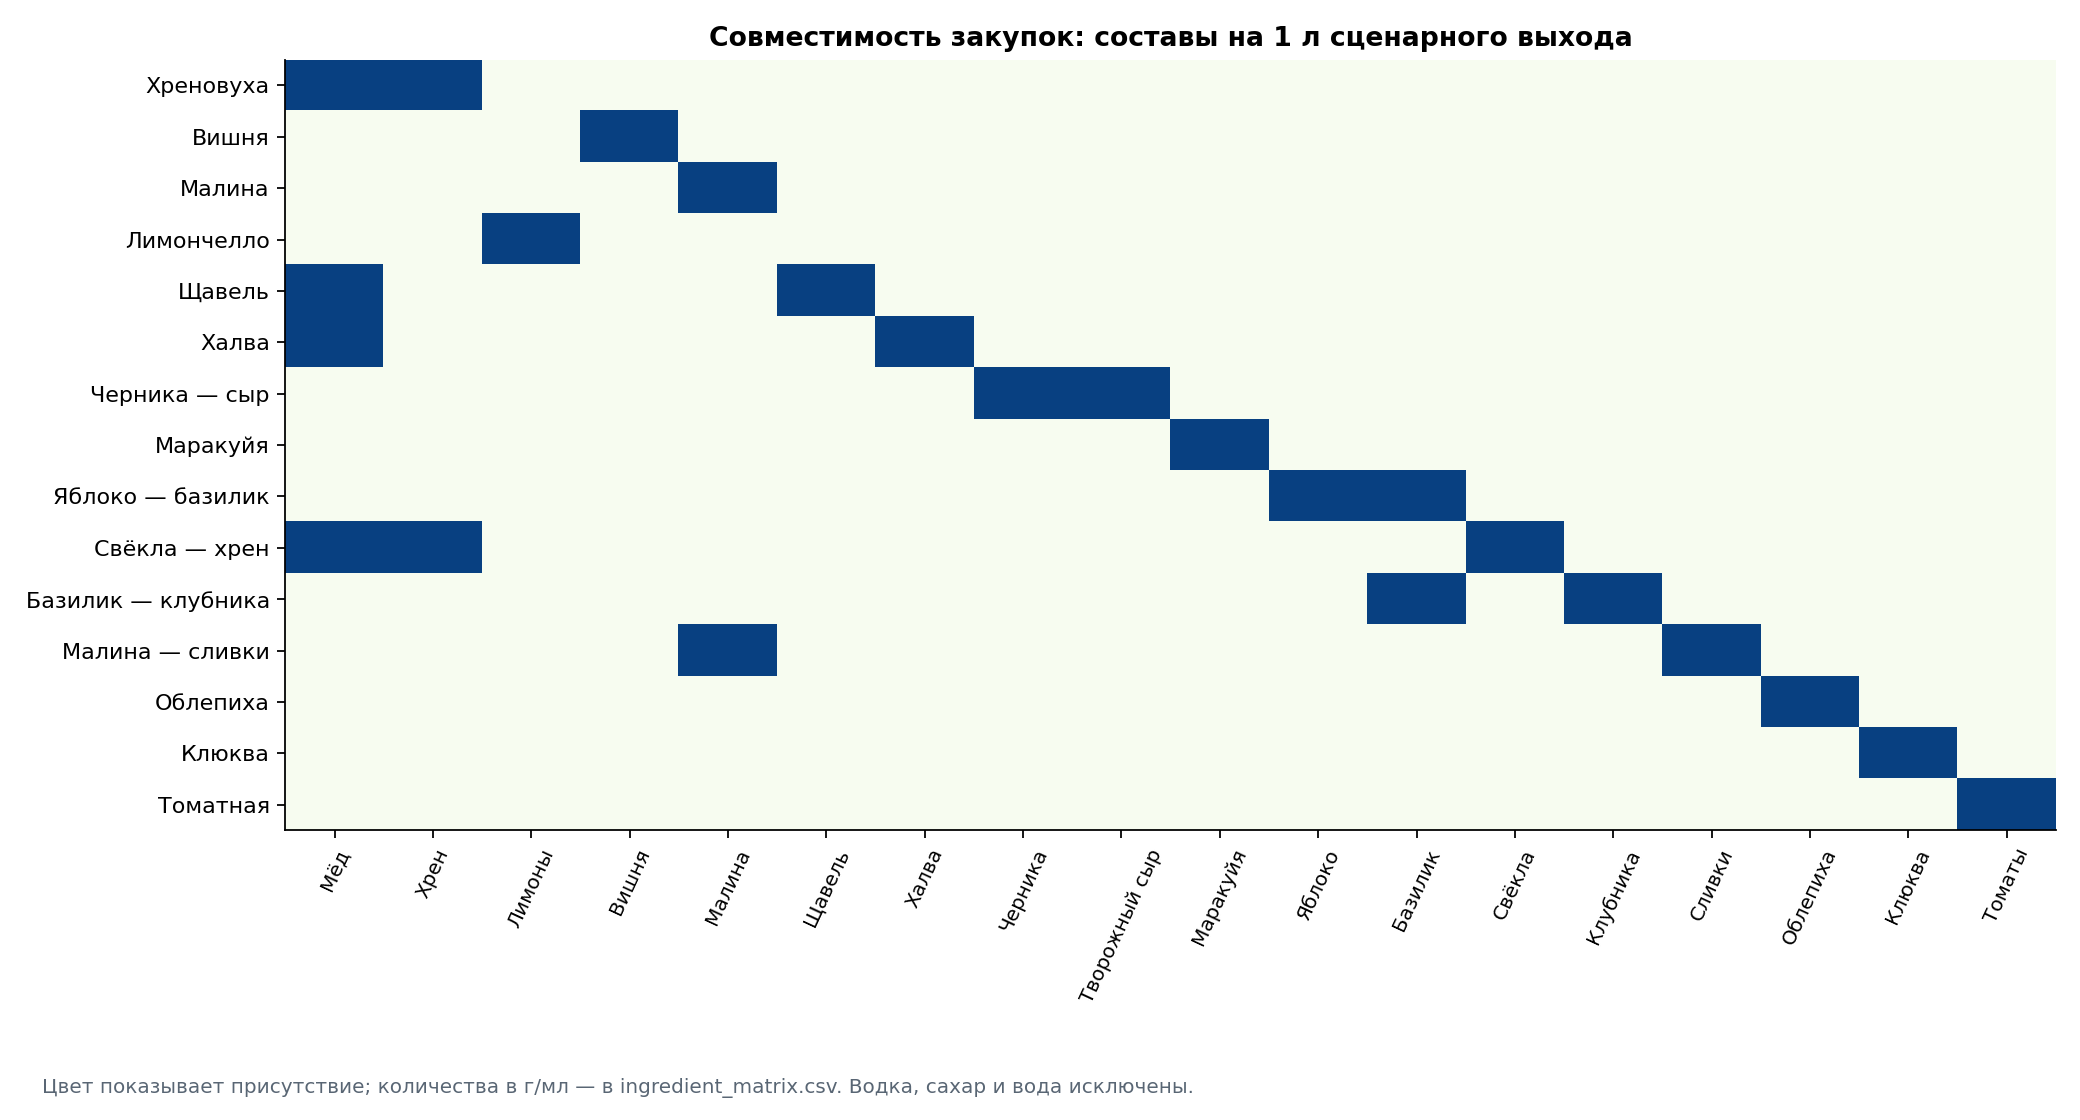

Матрица количеств на 1 л пригодного выхода: (15, 21)


**Меню A**

,normalized_flavor,tier,price_rub,cost_50ml_rub
0,Хреновуха,basic,230,90.66
1,Малина,basic,230,79.91
2,Лимончелло,basic,230,50.59
3,Щавель,basic,230,90.58
4,Халва,premium,330,72.56
5,Яблоко — базилик,basic,230,67.97
6,Свёкла — хрен,basic,230,70.31
7,Малина — сливки,premium,330,62.92
8,Облепиха,basic,230,61.88
9,Томатная,basic,230,62.60


**Меню B**

,normalized_flavor,tier,price_rub,cost_50ml_rub
10,Хреновуха,basic,230,90.66
11,Малина,basic,230,79.91
12,Лимончелло,basic,230,50.59
13,Щавель,basic,230,90.58
14,Халва,premium,330,72.56
15,Яблоко — базилик,basic,230,67.97
16,Свёкла — хрен,basic,230,70.31
17,Базилик — клубника,basic,230,66.78
18,Малина — сливки,premium,330,62.92
19,Томатная,basic,230,62.60


**Меню C**

,normalized_flavor,tier,price_rub,cost_50ml_rub
20,Хреновуха,basic,230,90.66
21,Малина,basic,230,79.91
22,Лимончелло,basic,230,50.59
23,Щавель,basic,230,90.58
24,Халва,premium,330,72.56
25,Черника — сыр,premium,330,83.06
26,Яблоко — базилик,basic,230,67.97
27,Свёкла — хрен,basic,230,70.31
28,Базилик — клубника,basic,230,66.78
29,Томатная,basic,230,62.60


,menu,purchase_cash_rub,consumed_cost_rub,leftover_value_rub,shared_nonuniversal_fraction,expensive_specific_recipes,high_risk_leftover_value_rub
0,A,"16,993.00","14,199.59","2,793.41",0.56,0,"1,906.02"
1,B,"17,009.00","14,297.60","2,711.40",0.61,0,"1,838.07"
2,C,"18,311.00","14,700.38","3,610.62",0.32,2,"1,938.69"


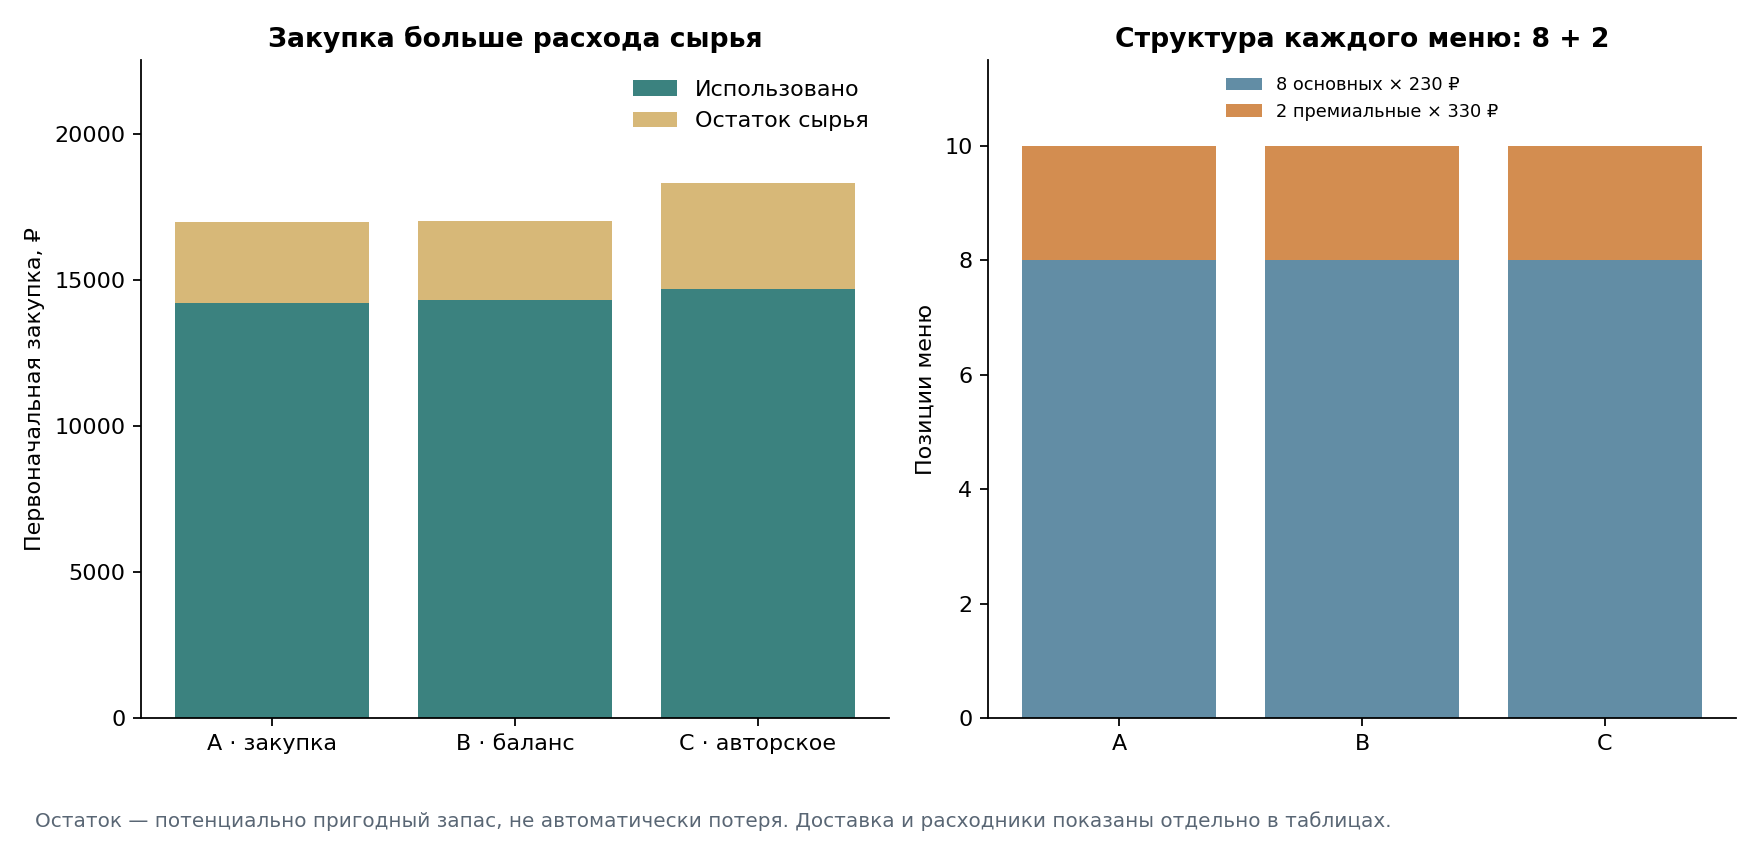

In [7]:
display(Image(filename=str(ROOT / "figures/economics/ingredient_use.png")))
quantities = pd.read_csv(out / "ingredient_matrix.csv", index_col="candidate_id")
print("Матрица количеств на 1 л пригодного выхода:", quantities.shape)
for name in ["A","B","C"]:
    display(Markdown(f"**Меню {name}**"))
    display(items.loc[items.menu.eq(name),["normalized_flavor","tier","price_rub","cost_50ml_rub"]])
display(menus[["menu","purchase_cash_rub","consumed_cost_rub","leftover_value_rub",
               "shared_nonuniversal_fraction","expensive_specific_recipes","high_risk_leftover_value_rub"]])
display(Image(filename=str(ROOT / "figures/economics/procurement_and_tiers.png")))

A и B почти одинаковы по первому заказу: 16 993 и 17 009 ₽. В B клубника с базиликом заменяет облепиху A, а базилик используется и в яблочной позиции. При замене малины на вишню отдельно понадобилась бы закупка вишни, а совместимость малиновой и сливочной позиций ухудшилась бы.

C с черникой и сыром требует 18 311 ₽; использованное сырьё — 14 700,38 ₽, остальной первый заказ остаётся запасом. В B использовано 14 297,60 ₽, остаток — 2 711,40 ₽. Доля общей неуниверсальной корзины B выше C. У B нет рецептур с дорогими специфическими закупками по выбранному определению, у C их две: малина и черника с сыром. Малина стала специфической после исключения малиновой сливочной позиции.

Свежий хрен даёт существенный остаток, но закупочный шаг 1 кг не подтверждён как минимальный. Поэтому разницу в 16 ₽ между A и B нельзя считать устойчивым экономическим преимуществом.

In [8]:
b = procurement.loc[procurement.menu.eq("B")].sort_values("leftover_value_rub",ascending=False)
display(b[["name","needed_base_quantity","base_unit","packages","purchase_cash_rub","consumed_cost_rub",
           "leftover_value_rub","recipes_using_ingredient","perishability"]].head(10))
display(menus[["menu","additional_cash_second_cycle_rub","cash_three_cycles_average_rub",
               "optional_delivery_scenario_rub","optional_consumables_scenario_rub","cash_with_optional_scenarios_rub"]])
display(pd.read_csv(out / "packaging_scenario.csv"))

,name,needed_base_quantity,base_unit,packages,purchase_cash_rub,consumed_cost_rub,leftover_value_rub,recipes_using_ingredient,perishability
19,Хрен корень,176.70,g,1,"1,900.00",335.73,"1,564.27",2,high
15,Водка Градус Арктик 40%,"7,851.01",ml,16,"11,616.00","11,399.66",216.34,10,low
25,Базилик зелёный свежий,45.88,g,1,299.00,137.17,161.83,2,high
27,Клубника замороженная,530.30,g,1,296.00,156.97,139.03,1,medium
24,Яблоко замороженное кубик,540.12,g,1,298.00,160.96,137.04,1,medium
21,Малина целая замороженная,845.86,g,1,838.00,708.83,129.17,2,medium
17,Вода питьевая негазированная,254.67,ml,1,117.00,5.96,111.04,1,low
28,Сливки 10%,239.23,ml,1,152.00,80.81,71.19,1,high
29,Томаты замороженные кубик,627.45,g,1,175.00,109.80,65.20,1,medium
23,Халва подсолнечная,830.45,g,4,332.00,275.71,56.29,1,medium


,menu,additional_cash_second_cycle_rub,cash_three_cycles_average_rub,optional_delivery_scenario_rub,optional_consumables_scenario_rub,cash_with_optional_scenarios_rub
0,A,"14,545.00","14,927.00",1500,200,"18,693.00"
1,B,"14,561.00","15,186.00",1500,200,"18,709.00"
2,C,"13,819.00","15,774.67",1500,200,"20,011.00"


,menu,ingredient_id,assumed_order_step,base_unit,purchase_cash_rub,delta_cash_rub,status
0,A,horseradish,100.00,g,"15,473.00","-1,520.00",assumed_availability_at_same_published_per_kg_...
1,B,horseradish,100.00,g,"15,489.00","-1,520.00",assumed_availability_at_same_published_per_kg_...
2,C,horseradish,100.00,g,"16,791.00","-1,520.00",assumed_availability_at_same_published_per_kg_...


Дополнительная закупка второго цикла учитывает пригодный запас первого заказа, а не повторяет всю корзину. Среднее за три одинаковых цикла — условный расчёт при сохранности сырья и повторном выпуске, не план фактических продаж. Остатки свежих и молочных продуктов выделены как риск, но не списаны целиком.

Отдельный сценарий доставки 250 ₽ на каждого из шести поставщиков и расходников 20 ₽ на каждую из десяти партий добавляет 1 700 ₽. Это неподтверждённые сценарные расходы. При условно доступном шаге хрена 100 г вместо 1 кг первая корзина уменьшается на 1 520 ₽; сама фасовка требует проверки. Себестоимость использованного хрена при той же ставке за кг не меняется.

## 7. Цель 250 ₽: цена меню и цена проданной порции

Простая средняя `(8×230 + 2×330)/10` = 250 ₽. Средняя продажи `230×(1−s)+330×s` достигает 250 ₽ только при доле премиальных порций `s=20%`. Доля относится к числу порций, не к выручке. Внутри каждого ценового уровня предполагаются равные доли вкусов.

5%, 20% и 35% — сценарии, не наблюдения и не прогноз. Отзывы в доли продаж не преобразуются.

Простая средняя меню: 250.0
Требуемая доля премиальных порций: 0.2


,menu,scenario,premium_share,weighted_price_rub,weighted_material_cost_50ml_rub,material_margin_50ml_rub,material_margin_fraction
0,A,low,0.05,235.00,71.61,163.39,0.70
1,A,base,0.20,250.00,71.00,179.00,0.72
2,A,high,0.35,265.00,70.39,194.61,0.73
9,B,low,0.05,235.00,72.19,162.81,0.69
10,B,base,0.20,250.00,71.49,178.51,0.71
11,B,high,0.35,265.00,70.79,194.21,0.73
18,C,low,0.05,235.00,72.69,162.31,0.69
19,C,base,0.20,250.00,73.50,176.50,0.71
20,C,high,0.35,265.00,74.31,190.69,0.72


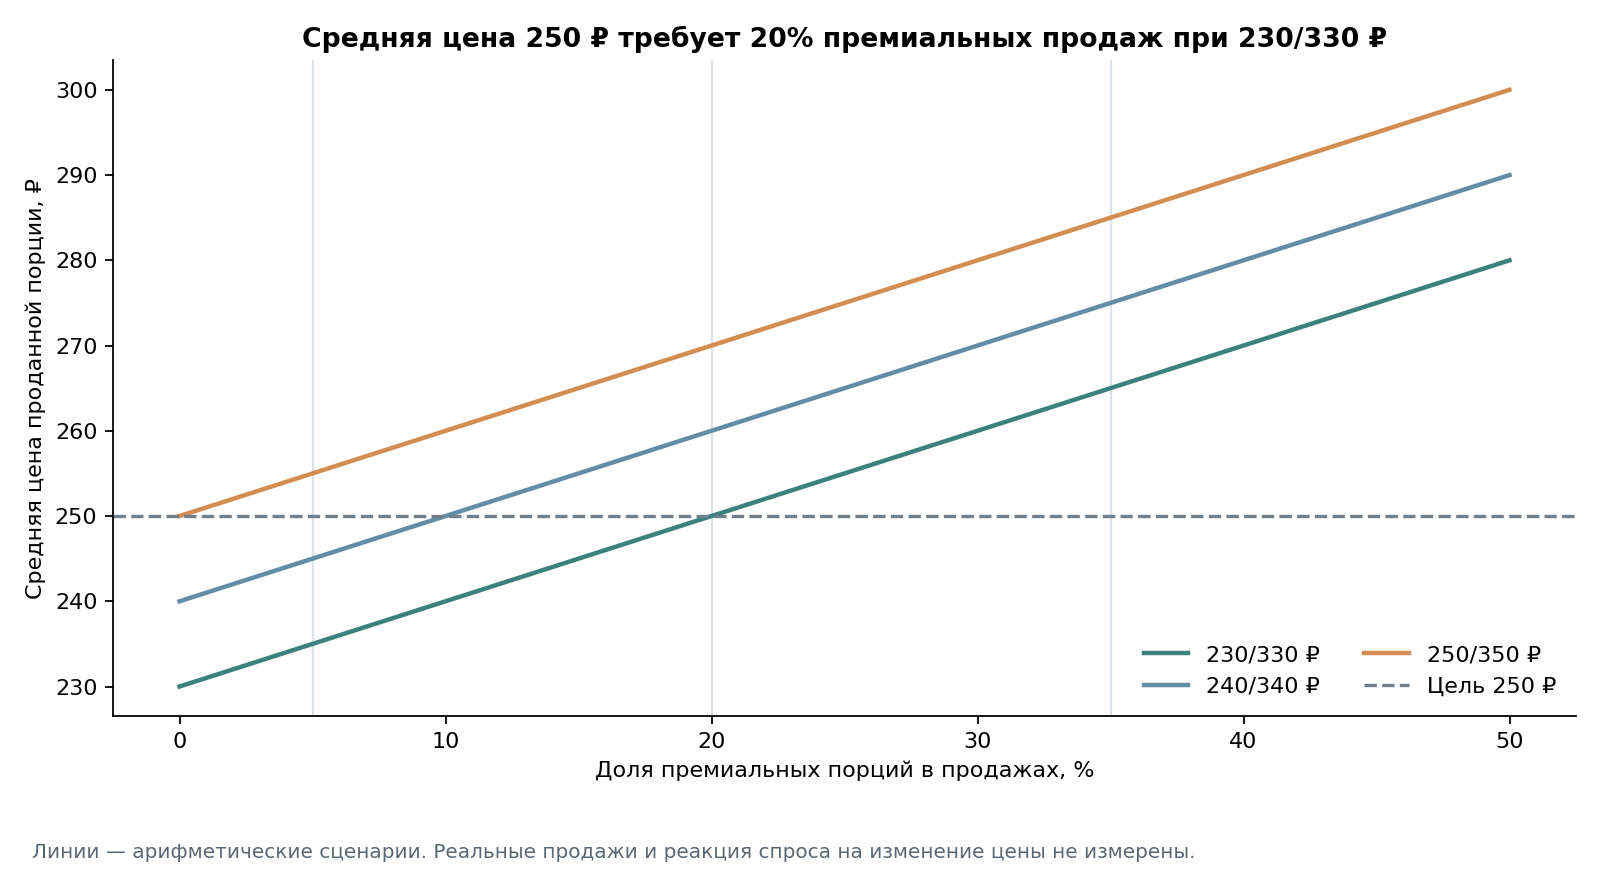

,basic_price_rub,premium_price_rub,scenario,simple_menu_price_rub,weighted_price_rub,required_premium_share_for_250,target_met
9,230,330,low,250.00,235.00,0.20,False
10,230,330,base,250.00,250.00,0.20,True
11,230,330,high,250.00,265.00,0.20,True
12,240,340,low,260.00,245.00,0.10,False
13,240,340,base,260.00,260.00,0.10,True
14,240,340,high,260.00,275.00,0.10,True
15,250,350,low,270.00,255.00,0.00,True
16,250,350,base,270.00,270.00,0.00,True
17,250,350,high,270.00,285.00,0.00,True


In [9]:
print("Простая средняя меню:",(8*230+2*330)/10)
print("Требуемая доля премиальных порций:", e.required_premium_share(230,330,250))
display(scenarios.loc[scenarios.price_pair.eq(0),["menu","scenario","premium_share","weighted_price_rub",
                 "weighted_material_cost_50ml_rub","material_margin_50ml_rub","material_margin_fraction"]])
display(Image(filename=str(ROOT / "figures/economics/price_mix.png")))
display(scenarios.loc[scenarios.menu.eq("B"),["basic_price_rub","premium_price_rub","scenario",
                 "simple_menu_price_rub","weighted_price_rub","required_premium_share_for_250","target_met"]])

При 5% премиальных средняя порция стоит 235 ₽ — цель не достигнута, хотя средняя десяти цен равна 250 ₽. При 20% — 250 ₽, при 35% — 265 ₽.

В B базовый сценарий даёт 178,51 ₽ материальной маржи на порцию, или 71,40%, до неучтённых расходов. Для цен 240/340 ₽ требуется 10% премиальных порций; 250/350 ₽ достигает цели уже без премиальных продаж. Но изменение цены может менять спрос, а эластичность не измерена. Эти альтернативы не являются готовым решением поднять цены.

## 8. Чувствительность и замена авторской позиции

Проверены рост всех закупочных цен на 10% и 20%, увеличение потерь жидкости на 10 процентных пунктов и низкая доля премиальных. Для каждого компонента отдельно рассчитано удорожание на 20%; это позволяет увидеть вклад алкогольной основы и других дорогих компонентов. Рост цены одного ингредиента не равен росту всей себестоимости на тот же процент.

In [10]:
stress = pd.read_csv(out / "stress_menu_scenarios.csv")
display(stress.loc[stress.menu.eq("B") & stress.mix_scenario.eq("base")])
sensitivity = pd.read_csv(out / "sensitivity.csv")
display(sensitivity.loc[sensitivity.menu.eq("B") & sensitivity.scenario.eq("price_plus_20"),
                        ["candidate_id","cost_50ml_rub","material_margin_fraction","below_margin_threshold"]])
component = pd.read_csv(out / "ingredient_price_sensitivity.csv")
display(component.sort_values("cost_50ml_increase_rub",ascending=False).head(8))
swaps = pd.read_csv(out / "substitutions.csv")
display(swaps.loc[swaps.removed.eq("C07")])

,menu,stress,mix_scenario,premium_share,weighted_price_rub,weighted_cost_50ml_rub,material_margin_50ml_rub,material_margin_fraction,positions_below_margin_threshold
13,B,base,base,0.20,250.00,71.49,178.51,0.71,0
16,B,loss_plus_10pp,base,0.20,250.00,80.54,169.46,0.68,2
19,B,price_plus_10,base,0.20,250.00,78.64,171.36,0.69,2
22,B,price_plus_20,base,0.20,250.00,85.79,164.21,0.66,3


,candidate_id,cost_50ml_rub,material_margin_fraction,below_margin_threshold
60,C01,108.79,0.53,True
61,C03,95.89,0.58,True
62,C04,60.70,0.74,False
63,C05,108.70,0.53,True
64,C06,87.07,0.74,False
65,C09,81.56,0.65,False
66,C10,84.37,0.63,False
67,C11,80.14,0.65,False
68,C12,75.51,0.77,False
69,C15,75.12,0.67,False


,candidate_id,ingredient_id,ingredient_price_increase,ingredient_cost_share,cost_50ml_increase_rub,new_cost_50ml_rub
0,C01,vodka,0.20,0.84,15.18,105.83
13,C05,vodka,0.20,0.75,13.67,104.26
32,C10,vodka,0.20,0.88,12.41,82.72
6,C03,vodka,0.20,0.74,11.79,91.70
3,C02,vodka,0.20,0.78,11.52,85.60
47,C14,vodka,0.20,0.82,11.52,81.60
50,C15,vodka,0.20,0.91,11.39,73.99
28,C09,vodka,0.20,0.82,11.20,79.17


,menu,removed,added,role,cash_delta_rub,consumed_delta_rub,review_score_delta
18,C,C07,C12,десертная,"-1,302.00",-402.79,0.75


В B рост закупочных цен на 20% снижает материальную маржу с 178,51 до 164,21 ₽ на условную порцию при неизменных ценах продажи и долях. Три позиции уходят ниже порога 60%. Дополнительные потери на 10 п.п. дают около 169,46 ₽ маржи, а две позиции перестают проходить порог.

В C замена «Черника — сыр» на «Малина — сливки» сохраняет 8+2 и обязательные направления, сокращает первый заказ на 1 302 ₽ и использованное сырьё на 402,79 ₽ для 10 л выпуска. Получается состав B. Это изменение вкуса и авторского образа, не технологически доказанная замена сыра другим ингредиентом. Выигрыш корзины складывается из удаления черники и сыра и возвращения общей закупки малины.

## 9. Что можно рекомендовать сейчас

**Взять B как основу пробных партий и проверки цен у поставщиков; финальное меню не утверждать.** A экономит лишь 16 ₽ первого заказа, а C с авторским якорем дороже и имеет более слабую опору в строгих отзывах. Сама модель не доказывает, что гости предпочтут B или купят 20% премиальных порций.

Следующие действия:

1. Проверить выход, фильтрационные потери, вкус, стабильность и хранение всех вариантов, особенно молочных. Заменить модельные количества утверждёнными технологическими картами.
2. Получить фактические цены и условия СПб, доступные фасовки, минимальные суммы заказов и доставку; отдельно проверить возможность небольшого заказа хрена.
3. Согласовать допустимую материальную маржинальность с полной сметой расходов. Не называть её чистой прибылью.
4. Проверить восприятие базовых и премиальных цен; затем собирать реальные продажи, доли вкусов и списания. Настроить выпуск по фактическому спросу.

Публичные отзывы остаются качественным ориентиром, а не оценкой продаж. Классификация вкусов, веса отбора, премиальный пул и авторский якорь — экспертные настройки, которые автор может изменить в конфигурации. Для всех расчётов сохранена связь с прежним справочником.

## 10. Контроль воспроизводимости

`python scripts/economics.py` повторяет расчёт без веб-запросов и обновляет только новые аналитические результаты. `python scripts/workbook.py validate` проверяет старую книгу без её записи. `python -m pytest -q` проверяет себестоимость, упаковки, остатки, потери, маржу, цены по долям продаж, SQL-срез и работу прежнего `refresh` на временной копии.

In [11]:
assert e.check_baseline()
assert len(candidates)==15
for name,group in items.groupby("menu"):
    assert len(group)==10 and group.candidate_id.is_unique
    assert group.tier.value_counts().to_dict()=={"basic":8,"premium":2}
assert abs(e.weighted_price(230,330,.20)-250)<1e-10
print("Исходные файлы и связи сохранены; три меню содержат ровно 10 позиций.")
print("Все результаты являются предварительными сценариями, не утверждёнными картами или прогнозом продаж.")

Исходные файлы и связи сохранены; три меню содержат ровно 10 позиций.
Все результаты являются предварительными сценариями, не утверждёнными картами или прогнозом продаж.
